
# Puhinui GRU — High-Water-Risk Classification

This notebook develops a **Puhinui-specific GRU** using the same core architecture and evaluation strategy used for Mahurangi, Otara, Swanson, and Wairau.

### Objective

Use the previous **48 hours** of:

- `rainfall_mm`
- `discharge_m3s`
- `water_level_m`

to estimate whether Puhinui is in a **high-water-risk window for the following 24 hours**.

### Target handling

The supplied `puhinui_modelling_dataset.csv` already contains:

- the three required hydrological inputs,
- the chronological `period`,
- and the prepared binary target `flood_risk_next_24h`.

The supplied target is retained so the GRU is evaluated against the same labels used by the team's other classifiers.

Because this is already a **filtered modelling dataset**, recalculating the original statistical threshold from only the retained training rows can slightly change the percentile. The notebook therefore audits the retained-row percentile and checks the target boundary, but it does **not overwrite the supplied target**.

### Leakage controls

- Scaling is fitted on Training data only.
- Probability threshold selection uses Validation only.
- Test is used only for final evaluation.
- The full hourly timeline is restored internally so GRU sequences never jump across missing timestamps.
- Only fully continuous 48-hour input windows inside a single data period are used.

The target represents **statistical high-water risk**, not independently verified historical flood occurrence.


## Fair Comparison with LSTM

This GRU experiment intentionally keeps the **same modelling protocol as the corresponding LSTM**:

- same catchment data and target;
- same chronological Training / Validation / Test periods;
- same three inputs: `rainfall_mm`, `discharge_m3s`, and `water_level_m`;
- same 48-hour lookback;
- same 24-hour high-water-risk prediction horizon;
- same training-only scaling;
- same class-imbalance weighting;
- same hidden size (32), dense layer (16), dropout (0.25), optimizer, learning rate, batch size, early stopping, and validation-based probability-threshold selection;
- same evaluation metrics and episode-level diagnostic.

The **recurrent unit is the main architectural change**: `nn.LSTM` is replaced by `nn.GRU`. This makes the GRU-vs-LSTM comparison substantially more controlled.

In [1]:

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cpu
CUDA available: False


## 1. Load the Puhinui Modelling Dataset

In [2]:

data_path = Path("puhinui_modelling_dataset.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "puhinui_modelling_dataset.csv was not found. "
        "Place it in the same folder as this notebook."
    )

source_data = pd.read_csv(data_path)

required_columns = [
    "timestamp",
    "period",
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",
    "flood_risk_next_24h",
]

missing_columns = [
    column
    for column in required_columns
    if column not in source_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

source_data["timestamp"] = pd.to_datetime(
    source_data["timestamp"],
    errors="coerce"
)

source_data = (
    source_data
    .sort_values("timestamp")
    .reset_index(drop=True)
)

feature_columns = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",
]

print("Source shape:", source_data.shape)
display(source_data.head())


Source shape: (88233, 39)


,timestamp,period,rainfall_mm,discharge_m3s,water_level_m,rainfall_sum_3h,rainfall_sum_6h,rainfall_sum_12h,rainfall_sum_24h,rainfall_sum_48h,rainfall_lag_1h,rainfall_lag_3h,rainfall_lag_6h,rainfall_lag_12h,rainfall_lag_24h,rainfall_lag_48h,discharge_lag_1h,discharge_lag_3h,discharge_lag_6h,discharge_lag_12h,discharge_lag_24h,discharge_lag_48h,water_level_lag_1h,water_level_lag_3h,water_level_lag_6h,water_level_lag_12h,water_level_lag_24h,water_level_lag_48h,discharge_change_1h,discharge_change_6h,discharge_change_24h,water_level_change_1h,water_level_change_6h,water_level_change_24h,month_sin,month_cos,hour_sin,hour_cos,flood_risk_next_24h
0,2015-01-03 01:00:00,Training,0.0,0.037,0.122,0.0,0.0,0.0,0.0,1.86,0.0,0.0,0.0,0.0,0.0,2.33,0.037,0.037,0.037,0.041,0.055,0.306,0.122,0.122,0.123,0.127,0.142,0.290,0.000,0.000,-0.018,0.000,-0.001,-0.020,0.5,0.866025,0.258819,0.965926,0
1,2015-01-03 02:00:00,Training,0.0,0.036,0.121,0.0,0.0,0.0,0.0,0.47,0.0,0.0,0.0,0.0,0.0,1.39,0.037,0.037,0.037,0.040,0.054,0.168,0.122,0.122,0.123,0.126,0.141,0.225,-0.001,-0.001,-0.018,-0.001,-0.002,-0.020,0.5,0.866025,0.500000,0.866025,0
2,2015-01-03 03:00:00,Training,0.0,0.036,0.121,0.0,0.0,0.0,0.0,0.47,0.0,0.0,0.0,0.0,0.0,0.00,0.036,0.037,0.037,0.040,0.052,0.127,0.121,0.122,0.123,0.126,0.139,0.199,0.000,-0.001,-0.016,0.000,-0.002,-0.018,0.5,0.866025,0.707107,0.707107,0
3,2015-01-03 04:00:00,Training,0.0,0.036,0.121,0.0,0.0,0.0,0.0,0.47,0.0,0.0,0.0,0.0,0.0,0.00,0.036,0.037,0.037,0.038,0.051,0.120,0.121,0.122,0.122,0.124,0.138,0.194,0.000,-0.001,-0.015,0.000,-0.001,-0.017,0.5,0.866025,0.866025,0.500000,0
4,2015-01-03 05:00:00,Training,0.0,0.036,0.121,0.0,0.0,0.0,0.0,0.47,0.0,0.0,0.0,0.0,0.0,0.00,0.036,0.036,0.037,0.038,0.049,0.134,0.121,0.121,0.122,0.124,0.136,0.204,0.000,-0.001,-0.013,0.000,-0.001,-0.015,0.5,0.866025,0.965926,0.258819,0


## 3. Audit the Supplied Dataset

In [3]:

print("Date range:")
print(
    source_data["timestamp"].min(),
    "to",
    source_data["timestamp"].max()
)

print("\nDuplicate timestamps:")
print(
    source_data["timestamp"].duplicated().sum()
)

print("\nMissing values in core GRU columns:")
print(
    source_data[
        [
            *feature_columns,
            "flood_risk_next_24h",
            "period",
        ]
    ].isna().sum()
)

print("\nRows by period:")
print(
    source_data[
        "period"
    ].value_counts()
)

time_difference = source_data["timestamp"].diff()

gap_mask = (
    time_difference.notna()
    & (
        time_difference
        != pd.Timedelta(hours=1)
    )
)

print("\nNon-hourly timestamp gaps:")
print(gap_mask.sum())

if gap_mask.sum() > 0:
    gap_audit = pd.DataFrame({
        "previous_timestamp":
            source_data["timestamp"].shift(1)[gap_mask],
        "next_timestamp":
            source_data.loc[gap_mask, "timestamp"],
        "gap":
            time_difference[gap_mask],
    })

    display(
        gap_audit
        .sort_values(
            "gap",
            ascending=False
        )
        .head(20)
    )


Date range:
2015-01-03 01:00:00 to 2025-12-31 00:00:00

Duplicate timestamps:
0

Missing values in core GRU columns:
rainfall_mm            0
discharge_m3s          0
water_level_m          0
flood_risk_next_24h    0
period                 0
dtype: int64

Rows by period:
period
Training      59545
Test          14423
Validation    14265
Name: count, dtype: int64

Non-hourly timestamp gaps:
160


,previous_timestamp,next_timestamp,gap
28873,2018-05-21 10:00:00,2019-03-08 00:00:00,290 days 14:00:00
19787,2017-04-14 00:00:00,2017-04-30 17:00:00,16 days 17:00:00
19854,2017-05-03 11:00:00,2017-05-10 09:00:00,6 days 22:00:00
1218,2015-02-22 18:00:00,2015-02-26 16:00:00,3 days 22:00:00
67905,2023-08-31 12:00:00,2023-09-02 12:00:00,2 days 00:00:00
2825,2015-05-04 14:00:00,2015-05-06 13:00:00,1 days 23:00:00
59545,2022-09-12 14:00:00,2022-09-13 15:00:00,1 days 01:00:00
73810,2024-05-07 07:00:00,2024-05-08 08:00:00,1 days 01:00:00
67906,2023-09-02 12:00:00,2023-09-03 12:00:00,1 days 00:00:00
2827,2015-05-06 14:00:00,2015-05-07 13:00:00,0 days 23:00:00



## 4. Restore the Complete Hourly Timeline

The supplied modelling dataset contains gaps where rows were removed during preprocessing and feature engineering.

For the GRU, an input sequence must represent **48 genuinely consecutive hours**. The complete hourly timeline is therefore restored internally.

Missing hours remain `NaN`; no rainfall, discharge, or water-level observations are invented.


In [4]:

hourly_timeline = pd.DataFrame({
    "timestamp": pd.date_range(
        start=source_data["timestamp"].min(),
        end=source_data["timestamp"].max(),
        freq="h"
    )
})

model_data = hourly_timeline.merge(
    source_data[
        [
            "timestamp",
            "period",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m",
            "flood_risk_next_24h",
        ]
    ],
    on="timestamp",
    how="left"
)

print("Restored hourly shape:", model_data.shape)
print(
    "Hourly rows restored as unavailable timestamps:",
    model_data["period"].isna().sum()
)

display(model_data.head())


Restored hourly shape: (96360, 6)
Hourly rows restored as unavailable timestamps: 8127


,timestamp,period,rainfall_mm,discharge_m3s,water_level_m,flood_risk_next_24h
0,2015-01-03 01:00:00,Training,0.0,0.037,0.122,0.0
1,2015-01-03 02:00:00,Training,0.0,0.036,0.121,0.0
2,2015-01-03 03:00:00,Training,0.0,0.036,0.121,0.0
3,2015-01-03 04:00:00,Training,0.0,0.036,0.121,0.0
4,2015-01-03 05:00:00,Training,0.0,0.036,0.121,0.0


## 5. Audit the Statistical High-Water Target

In [5]:

HIGH_WATER_PERCENTILE = 0.995

retained_training_levels = (
    model_data.loc[
        model_data["period"].eq("Training"),
        "water_level_m"
    ]
    .dropna()
)

retained_training_percentile = (
    retained_training_levels.quantile(
        HIGH_WATER_PERCENTILE
    )
)

print(
    "99.5th percentile using retained Training rows:",
    round(
        retained_training_percentile,
        4
    ),
    "m"
)

print(
    "\nNote: this dataset has already been filtered for modelling, "
    "so this retained-row percentile is an audit value, not a replacement "
    "for the threshold used to create the supplied target."
)


99.5th percentile using retained Training rows: 0.8483 m

Note: this dataset has already been filtered for modelling, so this retained-row percentile is an audit value, not a replacement for the threshold used to create the supplied target.


In [6]:

FORECAST_HORIZON = 24

future_water_levels = pd.concat(
    [
        model_data["water_level_m"].shift(-hour)
        for hour in range(
            1,
            FORECAST_HORIZON + 1
        )
    ],
    axis=1
)

future_24h_max = (
    future_water_levels.max(
        axis=1,
        skipna=False
    )
)

target_boundary_audit = pd.DataFrame({
    "supplied_target":
        model_data[
            "flood_risk_next_24h"
        ],
    "future_24h_max":
        future_24h_max,
}).dropna()

negative_maximum = (
    target_boundary_audit.loc[
        target_boundary_audit[
            "supplied_target"
        ].eq(0),
        "future_24h_max"
    ].max()
)

positive_minimum = (
    target_boundary_audit.loc[
        target_boundary_audit[
            "supplied_target"
        ].eq(1),
        "future_24h_max"
    ].min()
)

print(
    "Largest comparable future maximum labelled 0:",
    round(
        negative_maximum,
        4
    ),
    "m"
)

print(
    "Smallest comparable future maximum labelled 1:",
    round(
        positive_minimum,
        4
    ),
    "m"
)

print(
    "\nThe supplied labels imply a high-water decision boundary "
    "between these two values. The supplied target is retained unchanged."
)


Largest comparable future maximum labelled 0: 0.865 m
Smallest comparable future maximum labelled 1: 0.866 m

The supplied labels imply a high-water decision boundary between these two values. The supplied target is retained unchanged.


## 6. Review the Supplied Chronological Periods

In [7]:

period_summary = (
    model_data
    .dropna(
        subset=["period"]
    )
    .groupby("period")
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max"),
        positive_hours=(
            "flood_risk_next_24h",
            "sum"
        ),
    )
)

period_summary[
    "positive_percentage"
] = (
    100
    * period_summary[
        "positive_hours"
    ]
    / period_summary[
        "rows"
    ]
)

display(
    period_summary.loc[
        [
            "Training",
            "Validation",
            "Test"
        ]
    ].round(3)
)


,rows,beginning,ending,positive_hours,positive_percentage
period,,,,,
Training,59545,2015-01-03 01:00:00,2022-09-12 14:00:00,1406.0,2.361
Validation,14265,2022-09-13 15:00:00,2024-05-07 07:00:00,457.0,3.204
Test,14423,2024-05-08 08:00:00,2025-12-31 00:00:00,567.0,3.931


## 7. Identify Valid Continuous Input Hours

In [8]:

model_data["features_available"] = (
    model_data[
        feature_columns
    ]
    .notna()
    .all(axis=1)
)

missing_feature_rows = (
    ~model_data[
        "features_available"
    ]
)

print(
    "Hourly rows with at least one unavailable input:",
    missing_feature_rows.sum()
)

missing_groups = (
    missing_feature_rows
    .ne(
        missing_feature_rows.shift(
            fill_value=False
        )
    )
    .cumsum()
)

missing_episodes = (
    model_data.loc[
        missing_feature_rows
    ]
    .assign(
        missing_group=missing_groups[
            missing_feature_rows
        ]
    )
    .groupby("missing_group")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        hours=("timestamp", "size"),
    )
    .reset_index(drop=True)
)

print(
    "Unavailable-input episodes:",
    len(missing_episodes)
)

if len(missing_episodes) > 0:
    print(
        "Longest unavailable-input episode:",
        missing_episodes[
            "hours"
        ].max(),
        "hours"
    )

    display(
        missing_episodes
        .sort_values(
            "hours",
            ascending=False
        )
        .head(20)
    )


Hourly rows with at least one unavailable input: 8127
Unavailable-input episodes: 160
Longest unavailable-input episode: 6973 hours


,start,end,hours
22,2018-05-21 11:00:00,2019-03-07 23:00:00,6973
14,2017-04-14 01:00:00,2017-04-30 16:00:00,400
15,2017-05-03 12:00:00,2017-05-10 08:00:00,165
0,2015-02-22 19:00:00,2015-02-26 15:00:00,93
142,2023-08-31 13:00:00,2023-09-02 11:00:00,47
1,2015-05-04 15:00:00,2015-05-06 12:00:00,46
111,2022-09-12 15:00:00,2022-09-13 14:00:00,24
155,2024-05-07 08:00:00,2024-05-08 07:00:00,24
143,2023-09-02 13:00:00,2023-09-03 11:00:00,23
2,2015-05-06 15:00:00,2015-05-07 12:00:00,22


## 8. GRU Lookback

In [9]:

LOOKBACK_HOURS = 48

candidate_lookbacks = [
    24,
    48,
    72,
]

candidate_results = []

for lookback in candidate_lookbacks:

    complete_input_window = (
        model_data[
            "features_available"
        ]
        .astype(int)
        .rolling(
            window=lookback,
            min_periods=lookback
        )
        .sum()
        .eq(lookback)
    )

    for period_name in [
        "Training",
        "Validation",
        "Test"
    ]:

        same_period_window = (
            model_data[
                "period"
            ]
            .eq(period_name)
            .astype(int)
            .rolling(
                window=lookback,
                min_periods=lookback
            )
            .sum()
            .eq(lookback)
        )

        valid_samples = (
            complete_input_window
            & same_period_window
            & model_data[
                "flood_risk_next_24h"
            ].notna()
        )

        candidate_results.append({
            "lookback_hours":
                lookback,
            "period":
                period_name,
            "valid_samples":
                int(
                    valid_samples.sum()
                ),
        })

lookback_summary = pd.DataFrame(
    candidate_results
)

display(
    lookback_summary.pivot(
        index="lookback_hours",
        columns="period",
        values="valid_samples"
    )
)


period,Test,Training,Validation
lookback_hours,,,
24,14344,58260,13738
48,14296,57732,13498
72,14248,57208,13258


## 9. Scale Inputs Using Training Data Only

In [10]:

scaler_fit_mask = (
    model_data[
        "period"
    ].eq("Training")
    & model_data[
        "features_available"
    ]
)

scaler = StandardScaler()

scaler.fit(
    model_data.loc[
        scaler_fit_mask,
        feature_columns
    ]
)

scaled_features = np.full(
    (
        len(model_data),
        len(feature_columns)
    ),
    np.nan,
    dtype=np.float32
)

available_input_mask = (
    model_data[
        "features_available"
    ]
)

scaled_features[
    available_input_mask.to_numpy()
] = scaler.transform(
    model_data.loc[
        available_input_mask,
        feature_columns
    ]
).astype(np.float32)

print("Training means:")
display(
    pd.Series(
        scaler.mean_,
        index=feature_columns
    ).to_frame("mean")
)

print("\nTraining scales:")
display(
    pd.Series(
        scaler.scale_,
        index=feature_columns
    ).to_frame("scale")
)


Training means:


,mean
rainfall_mm,0.140724
discharge_m3s,0.234861
water_level_m,0.205326



Training scales:


,scale
rainfall_mm,0.799845
discharge_m3s,0.679001
water_level_m,0.126514


## 10. Convert the Hourly Series into GRU Sequences

In [11]:

from numpy.lib.stride_tricks import sliding_window_view

def create_sequences(
    data,
    scaled_feature_array,
    lookback,
    period_name,
):
    targets = (
        data[
            "flood_risk_next_24h"
        ]
        .to_numpy()
    )

    periods = (
        data[
            "period"
        ]
        .to_numpy()
    )

    feature_available = (
        np.isfinite(
            scaled_feature_array
        )
        .all(axis=1)
    )

    complete_feature_window = (
        pd.Series(
            feature_available.astype(int)
        )
        .rolling(
            window=lookback,
            min_periods=lookback
        )
        .sum()
        .to_numpy()
        == lookback
    )

    same_period_window = (
        pd.Series(
            (
                periods
                == period_name
            ).astype(int)
        )
        .rolling(
            window=lookback,
            min_periods=lookback
        )
        .sum()
        .to_numpy()
        == lookback
    )

    valid_end = (
        complete_feature_window
        & same_period_window
        & np.isfinite(targets)
    )

    end_indices = np.where(
        valid_end
    )[0]

    all_windows = (
        sliding_window_view(
            scaled_feature_array,
            window_shape=lookback,
            axis=0
        )
        .transpose(
            0,
            2,
            1
        )
    )

    window_positions = (
        end_indices
        - (lookback - 1)
    )

    X = (
        all_windows[
            window_positions
        ]
        .copy()
        .astype(np.float32)
    )

    y = (
        targets[
            end_indices
        ]
        .astype(np.float32)
    )

    timestamps = (
        data.loc[
            end_indices,
            "timestamp"
        ]
        .to_numpy()
    )

    return (
        X,
        y,
        timestamps,
        end_indices,
    )


In [12]:

X_train, y_train, train_timestamps, train_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "Training"
    )
)

X_validation, y_validation, validation_timestamps, validation_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "Validation"
    )
)

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)

print("\nPositive class percentage:")
print(
    "Training:",
    round(
        y_train.mean() * 100,
        3
    ),
    "%"
)

print(
    "Validation:",
    round(
        y_validation.mean() * 100,
        3
    ),
    "%"
)


X_train: (57732, 48, 3)
X_validation: (13498, 48, 3)

Positive class percentage:
Training: 2.383 %
Validation: 3.008 %


## 11. Handle Class Imbalance

In [13]:

negative_count = int(
    (y_train == 0).sum()
)

positive_count = int(
    (y_train == 1).sum()
)

positive_weight = (
    negative_count
    / positive_count
)

print(
    "Negative training samples:",
    negative_count
)

print(
    "Positive training samples:",
    positive_count
)

print(
    "Positive class weight:",
    round(
        positive_weight,
        3
    )
)


Negative training samples: 56356
Positive training samples: 1376
Positive class weight: 40.956


## 12. GRU Architecture

In [14]:

class GRUClassifier(
    nn.Module
):
    def __init__(
        self,
        input_size=3,
        hidden_size=32,
        dense_size=16,
        dropout=0.25,
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.dense = nn.Linear(
            hidden_size,
            dense_size
        )

        self.relu = nn.ReLU()

        self.output = nn.Linear(
            dense_size,
            1
        )

    def forward(
        self,
        x
    ):
        _, hidden_state = self.gru(x)

        x = hidden_state[-1]
        x = self.dropout(x)
        x = self.dense(x)
        x = self.relu(x)

        logits = self.output(x)

        return logits.squeeze(1)


model = GRUClassifier(
    input_size=len(
        feature_columns
    ),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

print(model)


GRUClassifier(
  (gru): GRU(3, 32, batch_first=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (dense): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=16, out_features=1, bias=True)
)


## 13. Train the GRU

In [15]:

torch.manual_seed(SEED)
np.random.seed(SEED)

BATCH_SIZE = 512
MAX_EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 0.001
MIN_DELTA = 1e-4

model = GRUClassifier(
    input_size=len(
        feature_columns
    ),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

loss_function = (
    nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            positive_weight,
            dtype=torch.float32
        )
    )
)

train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_train
        ),
        torch.from_numpy(
            y_train
        )
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

validation_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_validation
        ),
        torch.from_numpy(
            y_validation
        )
    ),
    batch_size=1024,
    shuffle=False,
)

best_validation_pr_auc = -np.inf
best_state = None
best_epoch = None
epochs_without_improvement = 0
training_history = []

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    model.train()
    total_loss = 0.0

    for (
        X_batch,
        y_batch
    ) in train_loader:

        optimizer.zero_grad()

        logits = model(
            X_batch
        )

        loss = loss_function(
            logits,
            y_batch
        )

        loss.backward()
        optimizer.step()

        total_loss += (
            loss.item()
            * len(y_batch)
        )

    epoch_loss = (
        total_loss
        / len(y_train)
    )

    model.eval()
    probability_parts = []

    with torch.no_grad():

        for (
            X_batch,
            _
        ) in validation_loader:

            probabilities = torch.sigmoid(
                model(
                    X_batch
                )
            )

            probability_parts.append(
                probabilities.cpu().numpy()
            )

    validation_probabilities = np.concatenate(
        probability_parts
    )

    validation_pr_auc = (
        average_precision_score(
            y_validation,
            validation_probabilities
        )
    )

    validation_roc_auc = (
        roc_auc_score(
            y_validation,
            validation_probabilities
        )
    )

    training_history.append({
        "epoch":
            epoch,
        "train_loss":
            epoch_loss,
        "validation_pr_auc":
            validation_pr_auc,
        "validation_roc_auc":
            validation_roc_auc,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={epoch_loss:.4f} | "
        f"val_PR_AUC={validation_pr_auc:.4f} | "
        f"val_ROC_AUC={validation_roc_auc:.4f}"
    )

    if (
        validation_pr_auc
        >
        best_validation_pr_auc
        + MIN_DELTA
    ):

        best_validation_pr_auc = (
            validation_pr_auc
        )

        best_state = copy.deepcopy(
            model.state_dict()
        )

        best_epoch = epoch
        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):
            print(
                "\nEarly stopping triggered."
            )
            break

model.load_state_dict(
    best_state
)

history_df = pd.DataFrame(
    training_history
)

print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best validation PR-AUC:",
    round(
        best_validation_pr_auc,
        4
    )
)


Epoch 01 | loss=1.2520 | val_PR_AUC=0.2215 | val_ROC_AUC=0.7501
Epoch 02 | loss=1.1196 | val_PR_AUC=0.2402 | val_ROC_AUC=0.7534
Epoch 03 | loss=1.0877 | val_PR_AUC=0.2408 | val_ROC_AUC=0.7554
Epoch 04 | loss=1.0830 | val_PR_AUC=0.2402 | val_ROC_AUC=0.7562
Epoch 05 | loss=1.0754 | val_PR_AUC=0.2407 | val_ROC_AUC=0.7566
Epoch 06 | loss=1.0751 | val_PR_AUC=0.2439 | val_ROC_AUC=0.7568
Epoch 07 | loss=1.0705 | val_PR_AUC=0.2458 | val_ROC_AUC=0.7569
Epoch 08 | loss=1.0717 | val_PR_AUC=0.2486 | val_ROC_AUC=0.7569
Epoch 09 | loss=1.0704 | val_PR_AUC=0.2506 | val_ROC_AUC=0.7570
Epoch 10 | loss=1.0688 | val_PR_AUC=0.2525 | val_ROC_AUC=0.7569
Epoch 11 | loss=1.0658 | val_PR_AUC=0.2543 | val_ROC_AUC=0.7569
Epoch 12 | loss=1.0677 | val_PR_AUC=0.2560 | val_ROC_AUC=0.7569
Epoch 13 | loss=1.0641 | val_PR_AUC=0.2573 | val_ROC_AUC=0.7568
Epoch 14 | loss=1.0619 | val_PR_AUC=0.2590 | val_ROC_AUC=0.7569
Epoch 15 | loss=1.0633 | val_PR_AUC=0.2607 | val_ROC_AUC=0.7568

Best epoch: 15
Best validation PR-AUC: 

## 14. Select the Probability Threshold Using Validation Only

In [16]:

model.eval()

with torch.no_grad():

    validation_probabilities = torch.sigmoid(
        model(
            torch.from_numpy(
                X_validation
            )
        )
    ).cpu().numpy()

(
    precision_curve,
    recall_curve,
    threshold_curve,
) = precision_recall_curve(
    y_validation,
    validation_probabilities
)

precision_for_threshold = (
    precision_curve[:-1]
)

recall_for_threshold = (
    recall_curve[:-1]
)

f2_curve = (
    5
    * precision_for_threshold
    * recall_for_threshold
    / (
        4
        * precision_for_threshold
        + recall_for_threshold
        + 1e-12
    )
)

best_threshold_position = (
    np.argmax(
        f2_curve
    )
)

selected_probability_threshold = float(
    threshold_curve[
        best_threshold_position
    ]
)

validation_predictions = (
    validation_probabilities
    >= selected_probability_threshold
).astype(int)

tn_val, fp_val, fn_val, tp_val = (
    confusion_matrix(
        y_validation,
        validation_predictions
    )
    .ravel()
)

validation_metrics = pd.Series({
    "threshold":
        selected_probability_threshold,
    "accuracy":
        accuracy_score(
            y_validation,
            validation_predictions
        ),
    "precision":
        precision_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_validation,
            validation_predictions,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_validation,
            validation_probabilities
        ),
    "pr_auc":
        average_precision_score(
            y_validation,
            validation_probabilities
        ),
    "true_positives":
        tp_val,
    "false_negatives":
        fn_val,
    "false_positives":
        fp_val,
    "true_negatives":
        tn_val,
})

display(
    validation_metrics
    .to_frame(
        "Validation"
    )
    .round(4)
)


,Validation
threshold,0.7853
accuracy,0.9458
precision,0.2305
recall,0.3424
f1_score,0.2755
f2_score,0.3121
roc_auc,0.7568
pr_auc,0.2607
true_positives,139.0000
false_negatives,267.0000


## 15. Final Evaluation on the Untouched Test Set

In [17]:

X_test, y_test, test_timestamps, test_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "Test"
    )
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


X_test: (14296, 48, 3)
y_test: (14296,)


In [18]:

model.eval()

test_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_test
        ),
        torch.from_numpy(
            y_test
        )
    ),
    batch_size=1024,
    shuffle=False,
)

test_probability_parts = []

with torch.no_grad():

    for (
        X_batch,
        _
    ) in test_loader:

        probabilities = torch.sigmoid(
            model(
                X_batch
            )
        )

        test_probability_parts.append(
            probabilities.cpu().numpy()
        )

test_probabilities = np.concatenate(
    test_probability_parts
)

test_predictions_binary = (
    test_probabilities
    >= selected_probability_threshold
).astype(int)

tn, fp, fn, tp = (
    confusion_matrix(
        y_test,
        test_predictions_binary
    )
    .ravel()
)

test_metrics = pd.Series({
    "selected_threshold":
        selected_probability_threshold,
    "accuracy":
        accuracy_score(
            y_test,
            test_predictions_binary
        ),
    "precision":
        precision_score(
            y_test,
            test_predictions_binary,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_test,
            test_predictions_binary,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_test,
            test_predictions_binary,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_test,
            test_predictions_binary,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_test,
            test_probabilities
        ),
    "pr_auc":
        average_precision_score(
            y_test,
            test_probabilities
        ),
    "true_positives":
        tp,
    "false_negatives":
        fn,
    "false_positives":
        fp,
    "true_negatives":
        tn,
})

display(
    test_metrics
    .to_frame(
        "Test"
    )
    .round(4)
)

print("\nClassification report:")

print(
    classification_report(
        y_test,
        test_predictions_binary,
        digits=4,
        zero_division=0
    )
)


,Test
selected_threshold,0.7853
accuracy,0.9449
precision,0.3186
recall,0.3422
f1_score,0.3299
f2_score,0.3372
roc_auc,0.7251
pr_auc,0.3066
true_positives,194.0000
false_negatives,373.0000



Classification report:
              precision    recall  f1-score   support

         0.0     0.9727    0.9698    0.9713     13729
         1.0     0.3186    0.3422    0.3299       567

    accuracy                         0.9449     14296
   macro avg     0.6457    0.6560    0.6506     14296
weighted avg     0.9468    0.9449    0.9458     14296



## 16. Test Diagnostic Plots

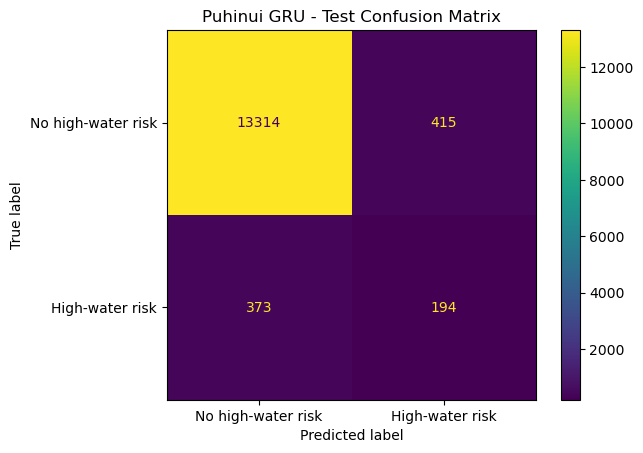

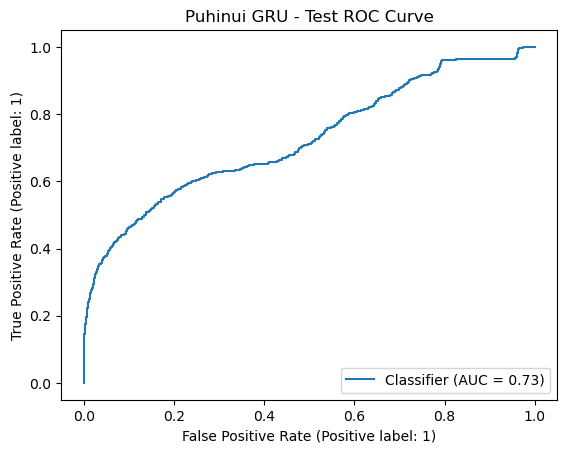

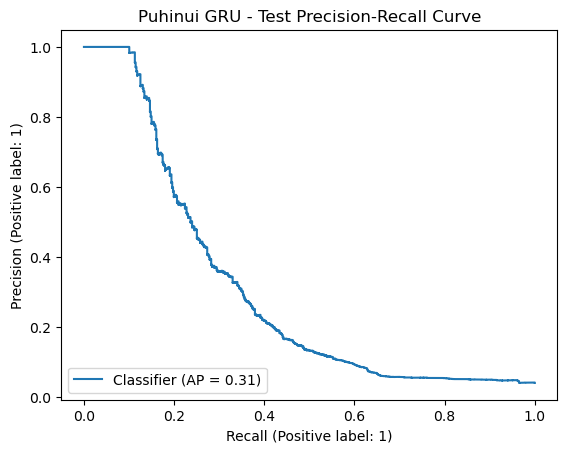

In [19]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions_binary,
    display_labels=[
        "No high-water risk",
        "High-water risk"
    ],
    values_format="d"
)

plt.title(
    "Puhinui GRU - Test Confusion Matrix"
)
plt.show()

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title(
    "Puhinui GRU - Test ROC Curve"
)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title(
    "Puhinui GRU - Test Precision-Recall Curve"
)
plt.show()


## 17. Hourly Test Predictions

In [20]:

test_predictions = pd.DataFrame({
    "timestamp":
        pd.to_datetime(
            test_timestamps
        ),
    "actual_risk":
        y_test.astype(int),
    "risk_probability":
        test_probabilities,
    "predicted_risk":
        test_predictions_binary.astype(int),
})

display(
    test_predictions.head()
)

print(
    "Prediction rows:",
    len(test_predictions)
)


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-10 07:00:00,0,0.233004,0
1,2024-05-10 08:00:00,0,0.232442,0
2,2024-05-10 09:00:00,0,0.233385,0
3,2024-05-10 10:00:00,0,0.233977,0
4,2024-05-10 11:00:00,0,0.234292,0


Prediction rows: 14296



## 18. Episode-Level Diagnostic Evaluation

Consecutive positive target hours are grouped into statistical high-water-risk episodes.

An episode is counted as detected if the GRU produces at least one positive prediction during that episode.

This does **not** mean that the episode is an independently verified historical flood.


In [21]:

full_test_target = (
    model_data.loc[
        model_data[
            "period"
        ].eq("Test")
        & model_data[
            "flood_risk_next_24h"
        ].notna(),
        [
            "timestamp",
            "flood_risk_next_24h",
        ]
    ]
    .rename(
        columns={
            "flood_risk_next_24h":
                "actual_risk"
        }
    )
    .copy()
)

full_test_target[
    "actual_risk"
] = (
    full_test_target[
        "actual_risk"
    ]
    .astype(int)
)

event_frame = (
    full_test_target
    .merge(
        test_predictions[
            [
                "timestamp",
                "risk_probability",
                "predicted_risk",
            ]
        ],
        on="timestamp",
        how="left"
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)

event_frame[
    "predicted_risk_for_detection"
] = (
    event_frame[
        "predicted_risk"
    ]
    .fillna(0)
    .astype(int)
)

actual_positive = (
    event_frame[
        "actual_risk"
    ]
    == 1
)

timestamp_gap = (
    event_frame[
        "timestamp"
    ]
    .diff()
    .ne(
        pd.Timedelta(
            hours=1
        )
    )
)

new_event = (
    actual_positive
    & (
        ~actual_positive.shift(
            fill_value=False
        )
        | timestamp_gap
    )
)

event_frame[
    "event_id"
] = (
    new_event
    .cumsum()
    .where(
        actual_positive
    )
)

event_level_results = (
    event_frame.loc[
        actual_positive
    ]
    .groupby(
        "event_id"
    )
    .agg(
        event_start=(
            "timestamp",
            "min"
        ),
        event_end=(
            "timestamp",
            "max"
        ),
        event_duration_hours=(
            "timestamp",
            "size"
        ),
        detected_hours=(
            "predicted_risk_for_detection",
            "sum"
        ),
        maximum_risk_score=(
            "risk_probability",
            "max"
        ),
        mean_risk_score=(
            "risk_probability",
            "mean"
        ),
    )
    .reset_index()
)

event_level_results[
    "event_detected"
] = (
    event_level_results[
        "detected_hours"
    ]
    > 0
)

event_level_results[
    "hourly_detection_percentage"
] = (
    100
    * event_level_results[
        "detected_hours"
    ]
    / event_level_results[
        "event_duration_hours"
    ]
)

display(
    event_level_results
)

event_detection_rate = (
    event_level_results[
        "event_detected"
    ]
    .mean()
    * 100
)

print(
    "\nEvent detection rate:",
    round(
        event_detection_rate,
        2
    ),
    "%"
)


,event_id,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
0,1.0,2024-05-19 23:00:00,2024-05-21 02:00:00,28,7,0.986166,0.457646,True,25.000000
1,2.0,2024-06-13 03:00:00,2024-06-14 13:00:00,35,11,0.982560,0.574123,True,31.428571
2,3.0,2024-06-16 00:00:00,2024-06-17 01:00:00,26,5,0.979277,0.606723,True,19.230769
3,4.0,2024-06-22 05:00:00,2024-06-23 06:00:00,26,7,0.981683,0.553328,True,26.923077
4,5.0,2024-08-31 02:00:00,2024-09-01 06:00:00,29,10,0.986617,0.639247,True,34.482759
5,6.0,2024-10-02 03:00:00,2024-10-03 05:00:00,27,11,0.983961,0.573126,True,40.740741
6,7.0,2024-11-14 14:00:00,2024-11-15 15:00:00,26,9,0.979724,0.596120,True,34.615385
7,8.0,2025-02-10 21:00:00,2025-02-11 20:00:00,24,3,0.963636,0.296429,True,12.500000
8,9.0,2025-04-18 03:00:00,2025-04-19 05:00:00,27,7,0.984234,0.624898,True,25.925926
9,10.0,2025-05-08 18:00:00,2025-05-09 20:00:00,27,14,0.984032,0.765143,True,51.851852



Event detection rate: 100.0 %


## 19. Save GRU Outputs

In [22]:

output_dir = (
    Path("outputs")
    / "puhinui_gru"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

torch.save(
    {
        "model_state_dict":
            model.state_dict(),
        "lookback_hours":
            LOOKBACK_HOURS,
        "feature_columns":
            feature_columns,
        "selected_probability_threshold":
            selected_probability_threshold,
    },
    output_dir
    / "puhinui_gru_model.pt"
)

joblib.dump(
    scaler,
    output_dir
    / "puhinui_gru_scaler.pkl"
)

test_predictions.to_csv(
    output_dir
    / "puhinui_gru_test_predictions.csv",
    index=False
)

event_level_results.to_csv(
    output_dir
    / "puhinui_gru_event_level_results.csv",
    index=False
)

validation_metrics.to_frame(
    "value"
).to_csv(
    output_dir
    / "puhinui_gru_validation_metrics.csv"
)

test_metrics.to_frame(
    "value"
).to_csv(
    output_dir
    / "puhinui_gru_test_metrics.csv"
)

history_df.to_csv(
    output_dir
    / "puhinui_gru_training_history.csv",
    index=False
)

print(
    "Saved outputs to:",
    output_dir.resolve()
)


Saved outputs to: C:\Users\lauso\AA Capstone Project\outputs\puhinui_gru
